<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/Clasificacion_Logit_Probit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelos de clasificación: MPL, logit y probit

Este notebook acompaña la Parte D de las slides del Día 4 y reproduce sus números. Ejemplo: **¿qué determina estar ocupado?** (EAH 2016, personas de 25 a 60 años).

Plan:
1. Datos
2. El modelo de probabilidad lineal (MPL) y sus fallas
3. Logit y probit
4. Efectos marginales
5. Bondad de ajuste
6. Más de dos categorías (logit multinomial)
7. Práctica

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

warnings.filterwarnings('ignore')

## 1. Datos

In [2]:
base = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/'

eah = pd.read_csv(base + 'eah2016_individual.csv')
c = eah[(eah['aesc'] != 99) & (eah['edad'].between(25, 60))].copy()
c['ocup'] = (c['estado'] == 'ocupado').astype(int)      # 1 = ocupado, 0 = desocupado o inactivo
c['mujer'] = (c['sexo'] == 'mujer').astype(int)
print('n =', len(c), '| porcentaje de ocupados:', round(100 * c['ocup'].mean()), '%')
c[['ocup', 'aesc', 'edad', 'mujer']].describe().round(2)

n = 6894 | porcentaje de ocupados: 84 %


,ocup,aesc,edad,mujer
count,6894.00,6894.00,6894.00,6894.00
mean,0.84,13.11,40.98,0.52
std,0.37,3.63,10.44,0.50
min,0.00,0.00,25.00,0.00
25%,1.00,12.00,32.00,0.00
50%,1.00,13.00,40.00,1.00
75%,1.00,16.00,50.00,1.00
max,1.00,19.00,60.00,1.00


## 2. El modelo de probabilidad lineal (MPL)

$P(ocup=1\mid x)=\beta_0+\beta_1 aesc+\beta_2 edad+\beta_3 edad^2+\beta_4 mujer$, estimado por MCO.

In [3]:
fm = 'ocup ~ aesc + edad + I(edad**2) + mujer'
lpm = smf.ols(fm, c).fit()
print(lpm.summary().tables[1])

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.2434      0.077      3.161      0.002       0.092       0.394
aesc             0.0158      0.001     13.294      0.000       0.013       0.018
edad             0.0241      0.004      6.398      0.000       0.017       0.031
I(edad ** 2)    -0.0003   4.46e-05     -6.544      0.000      -0.000      -0.000
mujer           -0.1496      0.009    -17.358      0.000      -0.166      -0.133


**Falla 1: predicciones fuera de $[0,1]$.**

In [4]:
print('Predicciones > 1:', int((lpm.fittedvalues > 1).sum()), f'({100 * (lpm.fittedvalues > 1).mean():.1f}%) | máximo = {lpm.fittedvalues.max():.2f} | predicciones < 0:', int((lpm.fittedvalues < 0).sum()))

Predicciones > 1: 304 (4.4%) | máximo = 1.04 | predicciones < 0: 0


**Falla 2: heterocedasticidad estructural**, $\Var(y\mid x)=p(1-p)$. Con errores robustos el MPL sigue siendo una buena primera aproximación.

In [5]:
bp = het_breuschpagan(lpm.resid, lpm.model.exog)
print(f'Breusch-Pagan sobre el MPL: LM = {bp[0]:.1f}, p = {bp[1]:.2g}')
print(pd.DataFrame({'EE convencional': lpm.bse, 'EE HC1': smf.ols(fm, c).fit(cov_type='HC1').bse}).round(4))

Breusch-Pagan sobre el MPL: LM = 522.5, p = 9.2e-112
              EE convencional  EE HC1
Intercept              0.0770  0.0817
aesc                   0.0012  0.0012
edad                   0.0038  0.0040
I(edad ** 2)           0.0000  0.0000
mujer                  0.0086  0.0085


## 3. Logit y probit
Estimación por **máxima verosimilitud**.

In [6]:
logit = smf.logit(fm, c).fit(disp=0)
probit = smf.probit(fm, c).fit(disp=0)
print(logit.summary().tables[1])
print('\nlog-verosimilitud:', round(logit.llf, 1), '| modelo sin regresores:', round(logit.llnull, 1), '| pseudo-R2 (McFadden):', round(logit.prsquared, 3))

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -2.6478      0.589     -4.493      0.000      -3.803      -1.493
aesc             0.1155      0.009     12.818      0.000       0.098       0.133
edad             0.1841      0.029      6.409      0.000       0.128       0.240
I(edad ** 2)    -0.0022      0.000     -6.526      0.000      -0.003      -0.002
mujer           -1.2190      0.075    -16.331      0.000      -1.365      -1.073

log-verosimilitud: -2823.2 | modelo sin regresores: -3067.2 | pseudo-R2 (McFadden): 0.08


**Interpretación de los coeficientes del logit:** $e^{\beta}$ es el factor por el que se multiplican los *odds* ante un aumento de una unidad.

In [7]:
print('odds ratio escolaridad:', round(np.exp(logit.params['aesc']), 3), '| odds ratio mujer:', round(np.exp(logit.params['mujer']), 3))

odds ratio escolaridad: 1.122 | odds ratio mujer: 0.296


Los coeficientes de MPL, logit y probit **no son comparables** entre sí. Lo que sí es comparable son los efectos marginales.

## 4. Efectos marginales

El efecto de $x_j$ sobre la probabilidad es $f(x'\beta)\,\beta_j$ y depende de $x$. Tres resúmenes: en un punto, **en la media (MEM)** y **promedio (AME)**.

In [8]:
ame_l = logit.get_margeff().summary_frame()['dy/dx']
ame_p = probit.get_margeff().summary_frame()['dy/dx']
mem_l = logit.get_margeff(at='mean').summary_frame()['dy/dx']
print(pd.DataFrame({'MPL (coef.)': lpm.params[['aesc', 'edad', 'mujer']], 'Logit AME': ame_l[['aesc', 'edad', 'mujer']],
                    'Probit AME': ame_p[['aesc', 'edad', 'mujer']], 'Logit MEM': mem_l[['aesc', 'edad', 'mujer']]}).round(4))

       MPL (coef.)  Logit AME  Probit AME  Logit MEM
aesc        0.0158     0.0146      0.0149     0.0139
edad        0.0241     0.0233      0.0238     0.0221
mujer      -0.1496    -0.1541     -0.1506    -0.1464


**El efecto depende del perfil:** un año más de escolaridad para un varón de 40 años que parte de 7 años de escolaridad y de otro que parte de 17.

In [9]:
def perfil(aesc, edad=40, mujer=0): return pd.DataFrame({'aesc': [aesc], 'edad': [edad], 'mujer': [mujer]})
for a0 in (7, 17):
    p0 = float(logit.predict(perfil(a0)).iloc[0]); p1 = float(logit.predict(perfil(a0 + 1)).iloc[0])
    print(f'aesc = {a0:2d}: P(ocupado) = {p0:.2f}; un año más agrega {p1 - p0:.4f}')
print('A los 12 años de escolaridad, varón vs. mujer (40 años):', round(float(logit.predict(perfil(12)).iloc[0]), 2), 'vs.', round(float(logit.predict(perfil(12, mujer=1)).iloc[0]), 2))

aesc =  7: P(ocupado) = 0.88; un año más agrega 0.0117
aesc = 17: P(ocupado) = 0.96; un año más agrega 0.0044
A los 12 años de escolaridad, varón vs. mujer (40 años): 0.93 vs. 0.79


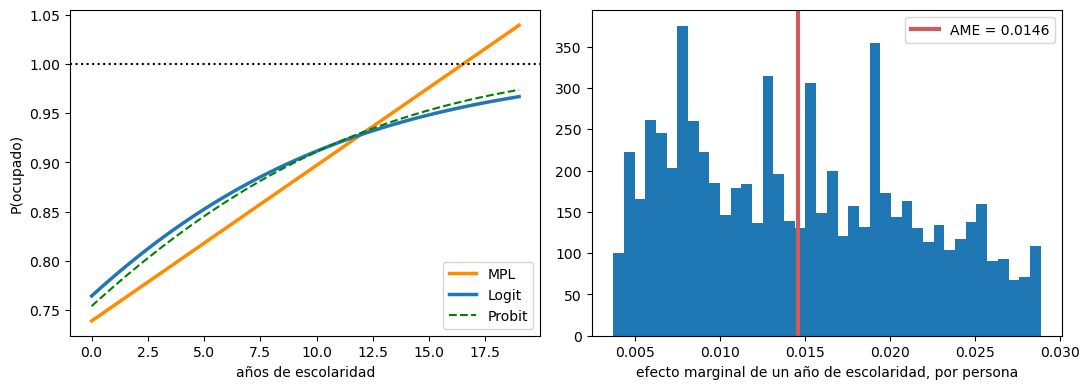

In [10]:
xs = np.linspace(0, 19, 100)
bs = pd.DataFrame({'aesc': xs, 'edad': 40, 'mujer': 0})
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(xs, lpm.predict(bs), label='MPL', lw=2.5, color='darkorange'); ax[0].plot(xs, logit.predict(bs), label='Logit', lw=2.5)
ax[0].plot(xs, probit.predict(bs), '--', label='Probit', color='green'); ax[0].axhline(1, color='k', ls=':'); ax[0].legend(); ax[0].set_xlabel('años de escolaridad'); ax[0].set_ylabel('P(ocupado)')
p_i = logit.predict(); ame_i = logit.params['aesc'] * p_i * (1 - p_i)
ax[1].hist(ame_i, bins=40); ax[1].axvline(ame_i.mean(), color='indianred', lw=3, label=f'AME = {ame_i.mean():.4f}'); ax[1].legend(); ax[1].set_xlabel('efecto marginal de un año de escolaridad, por persona')
plt.tight_layout(); plt.show()

## 5. Bondad de ajuste

Con una clase dominante (84% ocupados), la **tasa de aciertos** con umbral 0.5 casi no mejora a la de predecir siempre "ocupado". Es una medida pobre en este caso.

In [11]:
acc = ((logit.predict() > .5) == c['ocup']).mean()
print(f'Tasa de aciertos del logit (umbral 0.5): {100 * acc:.1f}% | predecir siempre la clase mayoritaria: {100 * max(c["ocup"].mean(), 1 - c["ocup"].mean()):.1f}%')

Tasa de aciertos del logit (umbral 0.5): 83.4% | predecir siempre la clase mayoritaria: 83.7%


## 6. Más de dos categorías: logit multinomial

`estado` tiene tres categorías sin orden (ocupado, desocupado, inactivo). El logit multinomial estima una ecuación por categoría respecto de una categoría de referencia (aquí, `ocupado`).

In [12]:
c['estado_cod'] = pd.Categorical(c['estado'], categories=['ocupado', 'desocupado', 'inactivo']).codes
mn = smf.mnlogit('estado_cod ~ aesc + edad + mujer', c).fit(disp=0)
print(mn.summary().tables[1] if len(mn.summary().tables) > 1 else mn.summary())
print(mn.get_margeff().summary())

estado_cod=1       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.8691      0.283     -3.067      0.002      -1.424      -0.314
aesc            -0.1137      0.014     -8.323      0.000      -0.140      -0.087
edad            -0.0175      0.005     -3.430      0.001      -0.027      -0.007
mujer            0.6456      0.107      6.053      0.000       0.437       0.855
--------------------------------------------------------------------------------
estado_cod=2       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -2.2390      0.235     -9.517      0.000      -2.700      -1.778
aesc            -0.1162      0.011    -10.909      0.000      -0.137      -0.095
edad             0.0135      0.004      3.442      0.001       0.006       0.021
mujer            1.6100     

## 7. Práctica

1. Agreguen la interacción `aesc:mujer` al logit. Calculen el AME de `aesc` para varones y para mujeres (pista: `get_margeff` sobre subconjuntos o predicciones con `perfil()`).
2. Comparen MPL, logit y probit en un perfil extremo (por ejemplo, `aesc = 0` y `edad = 60`). ¿Qué predice cada uno?
3. Usen un umbral distinto de 0.5 para clasificar (por ejemplo, 0.84) y calculen la tabla de confusión.
4. Agreguen una variable que les parezca relevante (por ejemplo, `inmigrante`) y comparen el AME de `aesc` antes y después.

In [13]:
# Espacio para trabajar